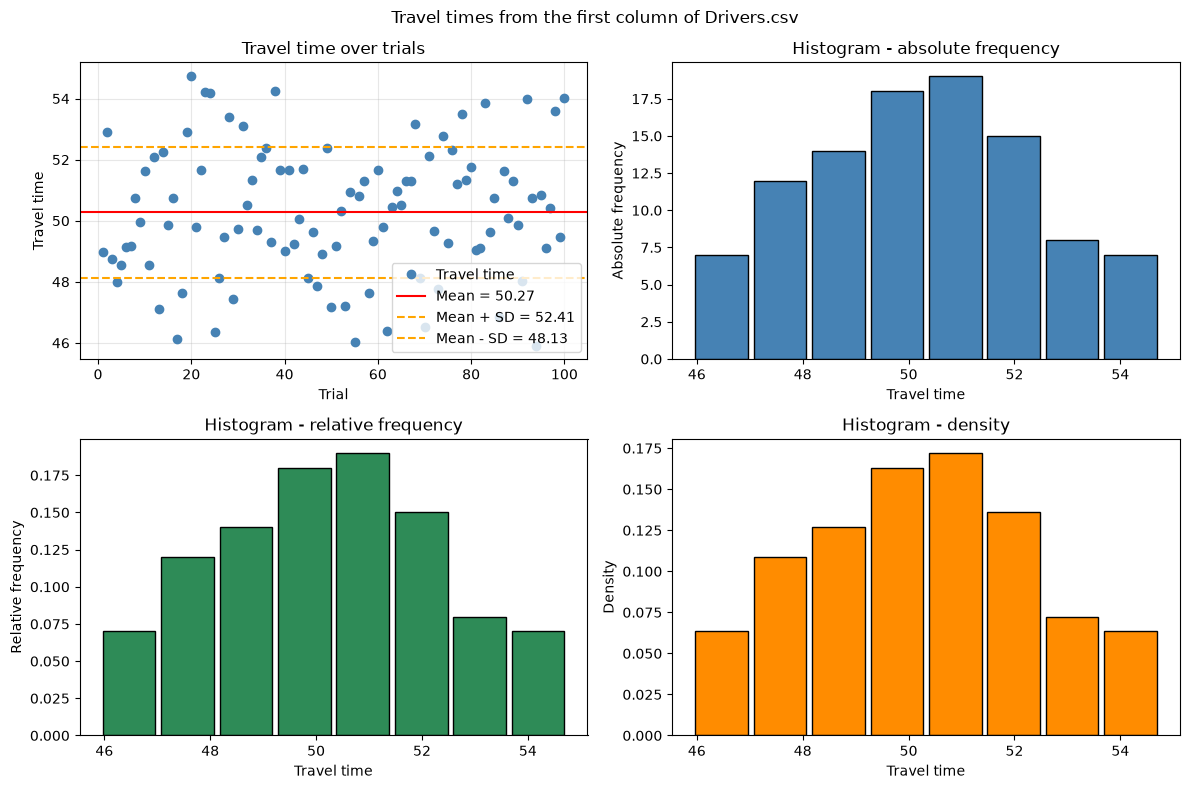

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Daten laden
df = pd.read_csv("../data/Drivers.csv", sep=";")

# Erste Spalte: cosy
data = df.iloc[:, 0].dropna().to_numpy(dtype=float)

# Kennwerte
mean_value = np.mean(data)
standard_deviation = np.std(data, ddof=1)

# Gemeinsame Klassenintervalle für alle Histogramme
bins = np.histogram_bin_edges(data, bins="auto")

# Eine Figure mit vier Diagrammen
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# -------------------------------------------------
# 1. Dot diagram: travel time over trials
# -------------------------------------------------
trials = np.arange(1, len(data) + 1)

axes[0, 0].plot(
    trials,
    data,
    "o",
    color="steelblue",
    label="Travel time"
)

axes[0, 0].axhline(
    mean_value,
    color="red",
    linestyle="-",
    label=f"Mean = {mean_value:.2f}"
)

axes[0, 0].axhline(
    mean_value + standard_deviation,
    color="orange",
    linestyle="--",
    label=f"Mean + SD = {mean_value + standard_deviation:.2f}"
)

axes[0, 0].axhline(
    mean_value - standard_deviation,
    color="orange",
    linestyle="--",
    label=f"Mean - SD = {mean_value - standard_deviation:.2f}"
)

axes[0, 0].set_title("Travel time over trials")
axes[0, 0].set_xlabel("Trial")
axes[0, 0].set_ylabel("Travel time")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# -------------------------------------------------
# 2. Histogram: absolute frequency
# -------------------------------------------------
axes[0, 1].hist(
    data,
    bins=bins,
    rwidth=0.9,
    edgecolor="black",
    color="steelblue"
)

axes[0, 1].set_title("Histogram - absolute frequency")
axes[0, 1].set_xlabel("Travel time")
axes[0, 1].set_ylabel("Absolute frequency")

# -------------------------------------------------
# 3. Histogram: relative frequency
# -------------------------------------------------
axes[1, 0].hist(
    data,
    bins=bins,
    rwidth=0.9,
    weights=np.ones_like(data) / len(data),
    edgecolor="black",
    color="seagreen"
)

axes[1, 0].set_title("Histogram - relative frequency")
axes[1, 0].set_xlabel("Travel time")
axes[1, 0].set_ylabel("Relative frequency")

# -------------------------------------------------
# 4. Histogram: density
# -------------------------------------------------
axes[1, 1].hist(
    data,
    bins=bins,
    rwidth=0.9,
    density=True,
    edgecolor="black",
    color="darkorange"
)

axes[1, 1].set_title("Histogram - density")
axes[1, 1].set_xlabel("Travel time")
axes[1, 1].set_ylabel("Density")

fig.suptitle("Travel times from the first column of Drivers.csv")
fig.tight_layout()
plt.show()